In [17]:
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import numpy as np  
from mlguess.data.dataset import LmdbDataset
import json
np.random.seed(777)

# Splits 
## Test (3,000)
## Train | Val (All-3,000)

In [3]:
dataset = LmdbDataset(path="/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_potential") 

In [4]:
N_samples = len(dataset)
N_samples

43597

In [5]:
indices = np.arange(N_samples)
test_idx = np.random.choice(indices, size=3_000, replace=False)
print(f"Test set size: {len(test_idx)}")
train_idx = np.setdiff1d(indices, test_idx)
print(f"Train set size: {len(train_idx)}")

Test set size: 3000
Train set size: 40597


In [6]:
val_idx = np.random.choice(train_idx, size=len(train_idx)//40, replace=False)
train_idx = np.setdiff1d(train_idx, val_idx)

In [7]:
print("Full dataset sizes:")
print(f"Train set size: {len(train_idx)}")
print(f"Validation set size: {len(val_idx)}")
print(f"Test set size: {len(test_idx)}")

Full dataset sizes:
Train set size: 39583
Validation set size: 1014
Test set size: 3000


In [8]:
unique_numbers_val = []
unique_numbers_test = []
unique_numbers_train = []

for idx in tqdm(val_idx):
    numbers = dataset[idx]['atom_types']
    unique_numbers_val.extend(numbers.detach().cpu().numpy().tolist())
    
for idx in tqdm(test_idx):
    numbers = dataset[idx]['atom_types']
    unique_numbers_test.extend(numbers.detach().cpu().numpy().tolist())

for idx in tqdm(train_idx):
    numbers = dataset[idx]['atom_types']
    unique_numbers_train.extend(numbers.detach().cpu().numpy().tolist())
    

  0%|          | 0/1014 [00:00<?, ?it/s]

100%|██████████| 39583/39583 [00:15<00:00, 2549.35it/s]


In [12]:
unique_numbers_count_val = {num: unique_numbers_val.count(num) for num in set(unique_numbers_val)}
unique_numbers_count_test = {num: unique_numbers_test.count(num) for num in set(unique_numbers_test)}
unique_numbers_count_train = {num: unique_numbers_train.count(num) for num in set(unique_numbers_train)}

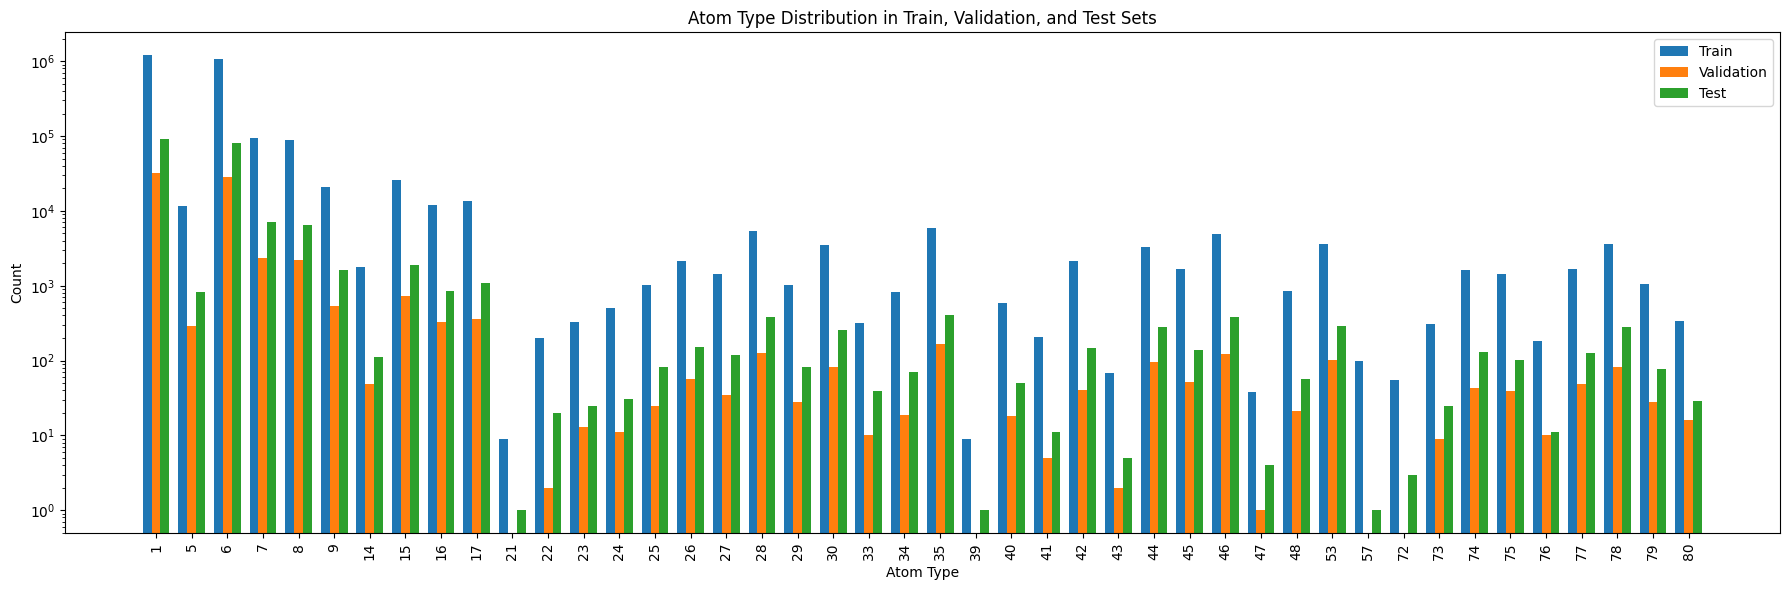

In [13]:
import matplotlib.pyplot as plt

# Get all unique atom types across all splits
all_atom_types = sorted(set(unique_numbers_count_val) | set(unique_numbers_count_test) | set(unique_numbers_count_train))

val_counts = [unique_numbers_count_val.get(atom, 0) for atom in all_atom_types]
test_counts = [unique_numbers_count_test.get(atom, 0) for atom in all_atom_types]
train_counts = [unique_numbers_count_train.get(atom, 0) for atom in all_atom_types]

x = np.arange(len(all_atom_types))
width = 0.25

plt.figure(figsize=(18, 6))
plt.bar(x - width, train_counts, width, label='Train')
plt.bar(x, val_counts, width, label='Validation')
plt.bar(x + width, test_counts, width, label='Test')

plt.xlabel('Atom Type')
plt.ylabel('Count')
plt.yscale('log')
plt.title('Atom Type Distribution in Train, Validation, and Test Sets')
plt.xticks(x, all_atom_types, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
split_indices = {
    "train": train_idx.tolist(),
    "validation": val_idx.tolist(),
    "test": test_idx.tolist()
}


# Save to a JSON file
output_json_path = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_potential/datasplits.json'
with open(output_json_path, 'w') as json_file:
    json.dump(split_indices, json_file)

print(f"Split indices saved to {output_json_path}")

Split indices saved to /home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_potential/datasplits.json


In [15]:
split_indices = {
    "train": train_idx.tolist()[:3000],
    "validation": val_idx.tolist(),
    "test": test_idx.tolist()
}


# Save to a JSON file
output_json_path = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_potential/datasplits_small.json'
with open(output_json_path, 'w') as json_file:
    json.dump(split_indices, json_file)

print(f"Split indices saved to {output_json_path}")

Split indices saved to /home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_potential/datasplits_small.json


# Shape Check

In [98]:
orbital_map_data = np.load("/home/ihor/projects/MLGuessQC/dxtb_experiments/dxtb_orbital_map.npz")
print(orbital_map_data.files)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82']


In [100]:
for idx in tqdm(indices):
    numbers = dataset[idx]['atom_types']
    potential = dataset[idx]['y']
    n_orb_total = 0
    for i, number in enumerate(numbers):
        n_orbitals = orbital_map_data[str(number.item())]
        n_orb_total += n_orbitals
    if potential.shape[0] != n_orb_total:
        print(f"Error in sample {idx}: expected {n_orb_total} orbitals, got {potential.shape[0]}")
        print(f"Atom types: {numbers}")
        print(f"Potential shape: {potential.shape}")
        raise ValueError("Mismatch in number of orbitals and potential shape.")
print("All samples have correct number of orbitals.")
        

100%|██████████| 21783/21783 [01:15<00:00, 289.78it/s]

All samples have correct number of orbitals.


# Splits without outliers

In [18]:
dataset = LmdbDataset(path="/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges") 

In [19]:
N_samples = len(dataset)
N_samples

43408

In [20]:
indices = np.arange(N_samples)
test_idx = np.random.choice(indices, size=3_000, replace=False)
print(f"Test set size: {len(test_idx)}")
train_idx = np.setdiff1d(indices, test_idx)
print(f"Train set size: {len(train_idx)}")

Test set size: 3000
Train set size: 40408


In [21]:
val_idx = np.random.choice(train_idx, size=3_000, replace=False)
train_idx = np.setdiff1d(train_idx, val_idx)

In [22]:
print("Full dataset sizes:")
print(f"Train set size: {len(train_idx)}")
print(f"Validation set size: {len(val_idx)}")
print(f"Test set size: {len(test_idx)}")

Full dataset sizes:
Train set size: 37408
Validation set size: 3000
Test set size: 3000


In [23]:
unique_numbers_val = []
unique_numbers_test = []
unique_numbers_train = []

for idx in tqdm(val_idx):
    numbers = dataset[idx]['atom_types']
    unique_numbers_val.extend(numbers.detach().cpu().numpy().tolist())
    
for idx in tqdm(test_idx):
    numbers = dataset[idx]['atom_types']
    unique_numbers_test.extend(numbers.detach().cpu().numpy().tolist())

for idx in tqdm(train_idx):
    numbers = dataset[idx]['atom_types']
    unique_numbers_train.extend(numbers.detach().cpu().numpy().tolist())

100%|██████████| 37408/37408 [00:14<00:00, 2576.03it/s]


In [24]:
unique_numbers_count_val = {num: unique_numbers_val.count(num) for num in set(unique_numbers_val)}
unique_numbers_count_test = {num: unique_numbers_test.count(num) for num in set(unique_numbers_test)}
unique_numbers_count_train = {num: unique_numbers_train.count(num) for num in set(unique_numbers_train)}

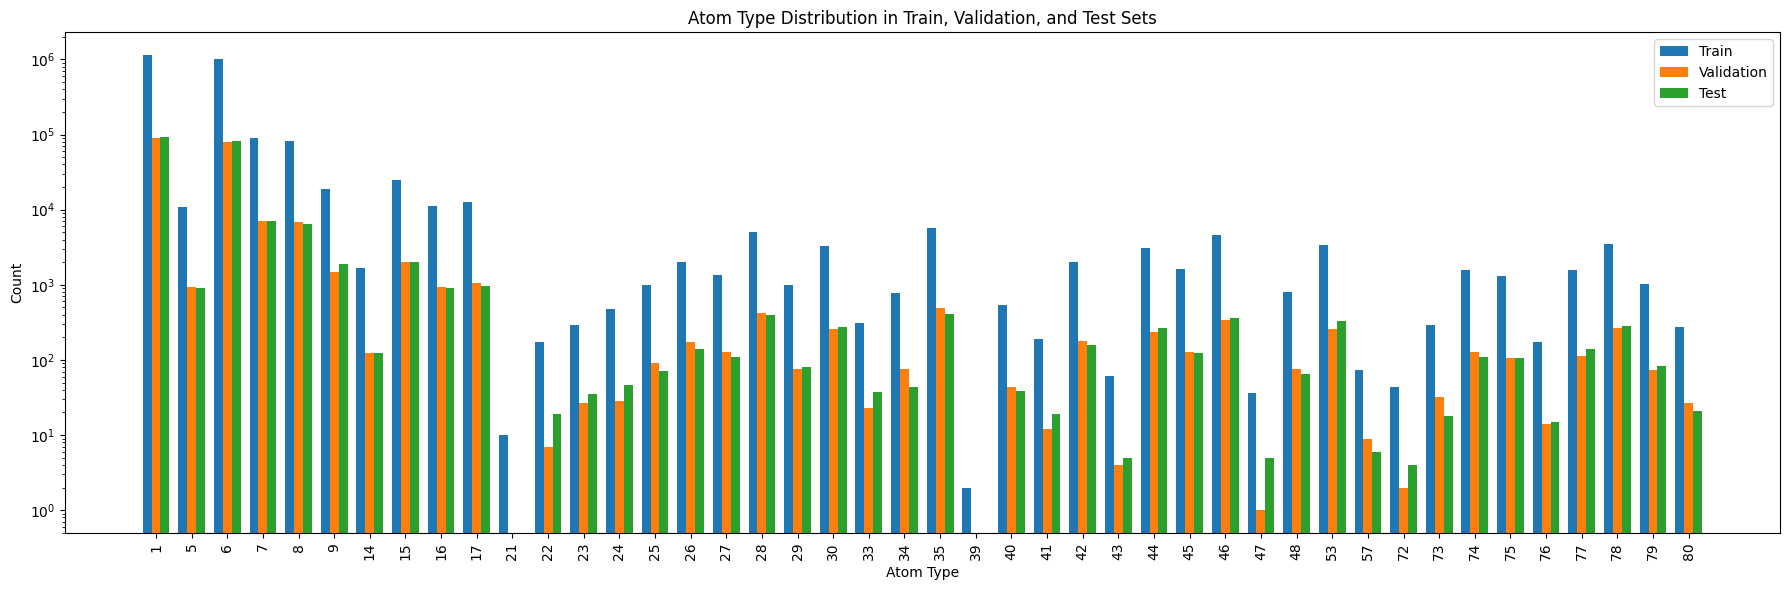

In [25]:
import matplotlib.pyplot as plt

# Get all unique atom types across all splits
all_atom_types = sorted(set(unique_numbers_count_val) | set(unique_numbers_count_test) | set(unique_numbers_count_train))

val_counts = [unique_numbers_count_val.get(atom, 0) for atom in all_atom_types]
test_counts = [unique_numbers_count_test.get(atom, 0) for atom in all_atom_types]
train_counts = [unique_numbers_count_train.get(atom, 0) for atom in all_atom_types]

x = np.arange(len(all_atom_types))
width = 0.25

plt.figure(figsize=(18, 6))
plt.bar(x - width, train_counts, width, label='Train')
plt.bar(x, val_counts, width, label='Validation')
plt.bar(x + width, test_counts, width, label='Test')

plt.xlabel('Atom Type')
plt.ylabel('Count')
plt.yscale('log')
plt.title('Atom Type Distribution in Train, Validation, and Test Sets')
plt.xticks(x, all_atom_types, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# split_indices = {
#     "train": train_idx.tolist(),
#     "validation": val_idx.tolist(),
#     "test": test_idx.tolist()
# }


# # Save to a JSON file
# output_json_path = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/datasplits.json'
# with open(output_json_path, 'w') as json_file:
#     json.dump(split_indices, json_file)

# print(f"Split indices saved to {output_json_path}")

Split indices saved to /home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/datasplits.json


In [27]:
test_idx.shape

(3000,)

# Overfit test set (for error vs acceleration plots)

In [28]:
split_indices = {
    "train": test_idx.tolist(),
    "validation": test_idx.tolist(),
    "test": test_idx.tolist()
}


# Save to a JSON file
output_json_path = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/datasplits_overfit.json'
with open(output_json_path, 'w') as json_file:
    json.dump(split_indices, json_file)

print(f"Split indices saved to {output_json_path}")

Split indices saved to /home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/datasplits_overfit.json


# Preding QM9 subset with model trained on tmQM

In [30]:
split_indices = {
    "train": [],
    "validation": [],
    "test": np.arange(0, 15_000).tolist()
}


# Save to a JSON file
output_json_path = '/home/ihor/projects/MLGuessQC/datasets/qm9_dxtb_converged/datasplits_qm9OOD_predict.json'
with open(output_json_path, 'w') as json_file:
    json.dump(split_indices, json_file)

print(f"Split indices saved to {output_json_path}")

Split indices saved to /home/ihor/projects/MLGuessQC/datasets/qm9_dxtb_converged/datasplits_qm9OOD_predict.json
